# Next-Latent Prediction: teaching a transformer to keep a compact state
*A from-scratch PyTorch walk-through of Teoh et al., [Next-Latent Prediction Transformers Learn Compact World Models](https://arxiv.org/abs/2511.05963) (Microsoft Research; NeurIPS 2026). All code is ours; all results labelled "paper" are Teoh et al.'s.*

**TL;DR.** A transformer predicts the next token by looking back at all earlier tokens, so nothing forces it to boil the past down to a small state. That is fine for next-token accuracy and risky for generalisation. NextLat adds one training-only loss: the model's final hidden state `h_t`, plus the next token `x_(t+1)`, must be enough for a small MLP to predict the *next* hidden state `h_(t+1)`. Teoh et al. prove that an ideal model trained this way has hidden states that are **belief states** (sufficient statistics of the history). They report, against next-token (GPT) training: on Manhattan taxi rides an **effective latent rank of 52.7 vs 160.1** and detour robustness 95% vs 85%; on Countdown 54.8% vs 39.2% for multi-token prediction at horizon 1; on a 1.3B-parameter model trained on 100B tokens an average zero-shot accuracy of 59.21 vs 58.82, and up to **3.3x faster inference** from self-speculative decoding. The cost: 1.40B vs 1.32B parameters during training (inference parameters unchanged) and, at horizon 1, the same 3.09 training steps per second as GPT.

<img src="nextlat_assets/fig1_mechanisms.png" width="760"/>

*Figure 1 of the paper. Left to right: next-token prediction, multi-token prediction, joint multi-token prediction and NextLat. Notice that only NextLat's extra target (red) lives in the model's own latent space rather than in token space.*

We could not reproduce the paper's scale. What we do instead is rebuild every piece in PyTorch, check each with code, and train GPT and NextLat on a **toy world** (a walled grid) where the true hidden state is known, so we can measure belief-state properties directly. Where our toy disagrees with the paper, we say so. Runtime is about 25 minutes on an Apple-silicon laptop, almost all of it training.

| step | question | what we build |
|---|---|---|
| 1 | What is the problem with plain next-token training? | a grid world where the true state is known |
| 2 | What is a belief state, and why would the loss produce one? | a numeric example, then Theorem 3.2's idea |
| 3 | What exactly is the NextLat loss? | the loss from the paper's Algorithm 1, with gradient checks |
| 4 | Does it change what a small transformer learns? | GPT vs NextLat, four measurements |
| 5 | Do the horizon and the KL term matter? | two ablations |
| 6 | Why can it speed up decoding? | self-speculative decoding, with a no-knowledge baseline |
| 7 | What did it cost, and what is open? | costs, our failures, claims without numbers |

In [1]:
import math, time
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0); np.random.seed(0)
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
GPT_C, NL_C, ACC_C = "#868e96", "#1c7ed6", "#d9480f"

CHECKS = []
def check(name, ok, detail=""):
    """Record + print PASS/FAIL. Every claim in this notebook is backed by one of these lines."""
    CHECKS.append((name, bool(ok)))
    print(("PASS  " if ok else "FAIL  ") + name + (f"   [{detail}]" if detail else ""))

## The shortcut problem

Start with a number. Teoh et al. use a dataset of random taxi rides in Manhattan (Vafa et al., 2024; 91M sequences, 4.7B tokens). The city has only **4,580 intersections**: the true "state" of a ride after any prefix is one of 4,580 values. A transformer trained to predict the next turn can reach 100% on the next-turn test, and the paper still finds its internal map has impossible streets. The cause they point to: self-attention can look anything up in the past, so there is no pressure to *compress* the past into the one state that matters.

We build the same situation at a size we can run. A grid with walls; a ride is a start cell followed by moves (up, down, left, right); the walk picks uniformly among **legal** moves. The hidden state is the current cell. A model that tracks it needs to know only which cell it is in; a lookup model can instead memorise histories.

In [2]:
class GridWorld:
    """A walled grid. The HIDDEN state is the current cell. A sequence is [start cell token, move, move, ...].
    Tokens 0-3 are moves (up, down, left, right); tokens 4... are 'start here' tokens, one per cell. The true next-move
    distribution is uniform over the LEGAL moves (the ones that do not hit a wall or the border)."""
    MOVES = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    def __init__(self, n=8, wall_frac=0.2, seed=0):
        rng = np.random.default_rng(seed); self.n = n
        while True:
            self.wall = rng.random((n, n)) < wall_frac
            if (~self.wall).sum() >= 0.6 * n * n: break
        self.open_cells = [(r, c) for r in range(n) for c in range(n) if not self.wall[r, c]]
        self.cell_id = {rc: i for i, rc in enumerate(self.open_cells)}
        self.n_cells, self.vocab = len(self.open_cells), 4 + n * n
        # legal[cell_index, move] and next_cell[cell_index, move]
        self.legal = np.zeros((self.n_cells, 4), bool); self.next_cell = np.zeros((self.n_cells, 4), int)
        for (r, c), i in self.cell_id.items():
            for m, (dr, dc) in enumerate(self.MOVES):
                rr, cc = r + dr, c + dc
                if 0 <= rr < n and 0 <= cc < n and not self.wall[rr, cc]: self.legal[i, m] = True; self.next_cell[i, m] = self.cell_id[(rr, cc)]
        self.has_move = self.legal.any(1)
        self.start_choices = np.nonzero(self.has_move)[0]
    def start_token(self, cell): r, c = self.open_cells[cell]; return 4 + r * self.n + c
    def sample(self, B, moves, rng, bias=None):
        """B walks of `moves` steps. Returns tokens (B, moves+1) and the cell after each token (B, moves+1).
        bias: optional length-4 weights (an OUT-OF-DISTRIBUTION walking style, e.g. always drifting right)."""
        cell = rng.choice(self.start_choices, B); toks = np.zeros((B, moves + 1), int); cells = np.zeros((B, moves + 1), int)
        toks[:, 0] = [self.start_token(c) for c in cell]; cells[:, 0] = cell
        w = np.ones(4) if bias is None else np.asarray(bias, float)
        for t in range(moves):
            p = self.legal[cell] * w; p = p / p.sum(1, keepdims=True)
            u = rng.random(B)[:, None]; m = (p.cumsum(1) < u).sum(1).clip(max=3)
            m = np.where(self.legal[cell, m], m, p.argmax(1))
            cell = self.next_cell[cell, m]; toks[:, t + 1] = m; cells[:, t + 1] = cell
        return torch.tensor(toks), torch.tensor(cells)
    def legal_mask_for(self, cells): return torch.tensor(self.legal[cells.numpy()])       # (..., 4) which moves are legal from these cells

50 open cells, vocabulary 68 (4 moves + 64 'start here' tokens)
history A: start (2, 6) then D U R D U D
history B: start (5, 7) then U D U U U D
both end at cell (3, 7)
legal next moves, A: ['U', 'D', 'L']   B: ['U', 'D', 'L']
PASS  two different histories that end in the same cell have exactly the same set of legal next moves


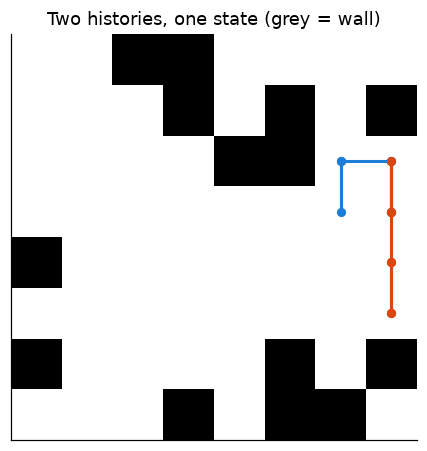

In [3]:
world = GridWorld(n=8, wall_frac=0.2, seed=0)
print(f"{world.n_cells} open cells, vocabulary {world.vocab} (4 moves + 64 'start here' tokens)")
rng = np.random.default_rng(0)
tok, cells = world.sample(2000, 6, rng)
# find two DIFFERENT histories that end in the same cell
seen, pair = {}, None
for i in range(len(tok)):
    key = int(cells[i, -1])
    if key in seen and not torch.equal(tok[i, 1:], tok[seen[key], 1:]) and int(cells[i, 0]) != int(cells[seen[key], 0]): pair = (seen[key], i); break
    seen.setdefault(key, i)
a, b = pair; names = "UDLR"
fmt = lambda i: f"start {world.open_cells[int(cells[i, 0])]} then " + " ".join(names[m] for m in tok[i, 1:].tolist())
print("history A:", fmt(a)); print("history B:", fmt(b)); print("both end at cell", world.open_cells[int(cells[a, -1])])
legalA, legalB = world.legal[int(cells[a, -1])], world.legal[int(cells[b, -1])]
print("legal next moves, A:", [names[m] for m in np.nonzero(legalA)[0]], "  B:", [names[m] for m in np.nonzero(legalB)[0]])
check("two different histories that end in the same cell have exactly the same set of legal next moves", bool((legalA == legalB).all()))

fig, ax = plt.subplots(figsize=(4.2, 4.2)); ax.imshow(world.wall, cmap="Greys", origin="upper"); ax.grid(False)
for i, col in [(a, "#1c7ed6"), (b, "#d9480f")]:
    xy = np.array([world.open_cells[int(c)] for c in cells[i]]); ax.plot(xy[:, 1], xy[:, 0], "o-", color=col, lw=2, ms=5)
ax.set_title("Two histories, one state (grey = wall)"); ax.set_xticks([]); ax.set_yticks([]); plt.tight_layout(); plt.show()

A model with a good world model should treat A and B identically after they meet, because the future depends only on the cell. A model that stores history can treat them differently and still be right on every training example. Next-token accuracy cannot tell these apart; we will need other measurements (step 4). First, the idea of what we want the hidden state to be.

## Belief states

**Concrete example.** In our grid, after a 24-move ride there are at most 4^24 = about 2.8 x 10^14 possible move sequences, but the future depends only on which of the 50 open cells we stand on. A 50-way summary loses nothing about the future.

**Definition (the paper's Definition 3.1).** A function `b_t = g(X_1..X_t)` of the history is a *belief state* if, for every bounded function `f` of the future, `E[f(future) | b_t] = E[f(future) | history]`. Equivalently `b_t` is a *sufficient statistic*: once you know it, the rest of the history adds nothing about the future.

We can check sufficiency in the toy by brute force. From the cell alone (the belief state) we can compute the exact distribution over the next two moves; from any history ending there we should get the same thing by simulation:

In [4]:
def two_step_dist_from_cell(world, cell):
    """Exact distribution over (move1, move2) computed from the cell alone."""
    d = np.zeros((4, 4)); l1 = world.legal[cell]; p1 = l1 / l1.sum()
    for m1 in range(4):
        if not l1[m1]: continue
        c2 = world.next_cell[cell, m1]
        if not world.has_move[c2]: continue
        l2 = world.legal[c2]; d[m1] = p1[m1] * l2 / l2.sum()
    return d

target_cell = int(cells[a, -1]); exact = two_step_dist_from_cell(world, target_cell)
# Monte Carlo from many DIFFERENT histories that all end in target_cell: continue each one for two steps.
rng = np.random.default_rng(1); counts = np.zeros((4, 4)); n = 0
for _ in range(60000):
    t_, c_ = world.sample(1, 8, rng)
    if int(c_[0, -1]) != target_cell: continue
    m1 = (rng.random() < np.cumsum(world.legal[target_cell] / world.legal[target_cell].sum())).argmax()
    c2 = world.next_cell[target_cell, m1]
    if not world.has_move[c2]: continue
    m2 = (rng.random() < np.cumsum(world.legal[c2] / world.legal[c2].sum())).argmax(); counts[m1, m2] += 1; n += 1
mc = counts / n
print(f"{n} histories ended at cell {world.open_cells[target_cell]}; max |exact - simulated| over the 16 move pairs: {np.abs(exact / exact.sum() - mc).max():.3f}")
check("the cell is a belief state here: the future distribution computed from the cell alone matches simulation over many histories", np.abs(exact / exact.sum() - mc).max() < 0.03)

1268 histories ended at cell (3, 7); max |exact - simulated| over the 16 move pairs: 0.011
PASS  the cell is a belief state here: the future distribution computed from the cell alone matches simulation over many histories


**Why next-token training alone does not guarantee this.** Teoh et al. cite Hu et al. (2025, Belief State Transformers) for the fact that a transformer can reach the optimal next-token loss without its hidden state being a belief state: attention can fetch whatever past tokens the prediction needs.

**What NextLat adds (Theorem 3.2, intuition first).** Ask for two consistencies:

1. *next-token consistency*: a head decodes the next token from `h_t`, `p_theta(x_(t+1) | h_t) = P(x_(t+1) | x_1..x_t)`;
2. *transition consistency*: a small model predicts the next hidden state from the current one and the next token alone, `p_psi(h_(t+1) | h_t, x_(t+1)) = P(h_(t+1) | x_1..x_(t+1))`.

If both hold, the future can be generated from `h_t` by chaining them: decode a token, update the state, decode again, and so on, **without ever looking at the earlier tokens again**. That is only possible if `h_t` already contains everything about the past that matters for the future, i.e. it is a belief state. The theorem is about an *idealised* model that optimises both objectives perfectly; a trained network only approximates that, which is why we measure rather than assume (step 4). The paper notes the result already holds for horizon `d = 1`.

## The NextLat loss

Three terms (the paper's equation 5):

&nbsp;&nbsp;&nbsp;&nbsp;`L = L_next-token + lambda_h * L_next-h + lambda_KL * L_KL`

* **`L_next-token`**: ordinary cross-entropy. Nothing changes here.
* **`L_next-h`**: run a small MLP `p_psi` on `(h_t, x_(t+1))` to get `h_hat_(t+1)`, and compare with the transformer's actual `h_(t+1)` using a Smooth-L1 loss. The target `h_(t+1)` is **stop-gradiented** (treated as a constant), a standard trick in self-predictive learning to avoid collapse. With horizon `d > 1` the MLP is applied recursively and every intermediate step is supervised (teacher-forced tokens).
* **`L_KL`**: push the *token distribution decoded from the predicted state* toward the one decoded from the real state, using the **frozen** output head, so the gradient flows only into the dynamics model. It is a form of distillation and adds meaning to `h_hat`.

During inference the dynamics MLP is not needed at all: the transformer is unchanged. (We use it in step 6 to speed decoding up.) The code below is a direct implementation of the paper's Algorithm 1, with one decision worth naming: the dynamics model gets its own token embedding.

In [5]:
class Block(nn.Module):
    def __init__(self, d, heads):
        super().__init__(); self.n1, self.n2 = nn.LayerNorm(d), nn.LayerNorm(d); self.h = heads
        self.qkv, self.proj = nn.Linear(d, 3 * d), nn.Linear(d, d); self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
    def forward(self, x):
        B, T, D = x.shape; q, k, v = self.qkv(self.n1(x)).view(B, T, 3, self.h, D // self.h).permute(2, 0, 3, 1, 4)
        x = x + self.proj(F.scaled_dot_product_attention(q, k, v, is_causal=True).transpose(1, 2).reshape(B, T, D))
        return x + self.mlp(self.n2(x))

def sinusoid(T, d):
    pos = torch.arange(T)[:, None].float(); i = torch.arange(0, d, 2)[None].float(); a = pos / (10000 ** (i / d))
    return torch.cat([torch.sin(a), torch.cos(a)], -1)

class GPT(nn.Module):
    """A small decoder-only transformer (nanoGPT style). hidden(tokens) returns the FINAL-layer states h_t (B, T, D): the
    'latent state' NextLat reasons about. Positions are fixed sinusoids so we can test longer sequences than we trained on."""
    def __init__(self, vocab, d=128, layers=4, heads=4):
        super().__init__(); self.d = d; self.emb = nn.Embedding(vocab, d); self.blocks = nn.ModuleList(Block(d, heads) for _ in range(layers))
        self.norm = nn.LayerNorm(d); self.head = nn.Linear(d, vocab)
    def hidden(self, tok):
        x = self.emb(tok) + sinusoid(tok.shape[1], self.d).to(tok.device)
        for b in self.blocks: x = b(x)
        return self.norm(x)
    def forward(self, tok): h = self.hidden(tok); return self.head(h), h

In [6]:
class LatentDynamics(nn.Module):
    """p_psi(h_{t+1} | h_t, x_{t+1}): a small MLP that predicts the NEXT hidden state from the current one and the next token."""
    def __init__(self, d, vocab, width=None):
        super().__init__(); width = width or d; self.tok = nn.Embedding(vocab, d)
        self.net = nn.Sequential(nn.Linear(2 * d, width), nn.GELU(), nn.Linear(width, d))
    def forward(self, h, next_tok): return self.net(torch.cat([h, self.tok(next_tok)], -1))

def nextlat_loss(model, dyn, tokens, horizon=1, lam_h=1.0, lam_kl=1.0, use_kl=True):
    """L = L_next-token + lam_h * L_next-h + lam_kl * L_KL     (paper eq. 5, Algorithm 1).
    tokens: (B, T). Returns (total loss, dict of parts)."""
    inp, tgt = tokens[:, :-1], tokens[:, 1:]
    logits, h = model(inp)                                                              # h: (B, T-1, D) final hidden states
    l_tok = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), tgt.reshape(-1))      # ordinary next-token loss
    cur, nxt_tok, nxt_h, post = h, inp, h, logits
    l_h, l_kl = 0.0, 0.0
    for _ in range(horizon):                                                             # recursive d-step rollout
        cur, nxt_tok, nxt_h, post = cur[:, :-1], nxt_tok[:, 1:], nxt_h[:, 1:], post[:, 1:]  # align (h_t, x_{t+1}) -> h_{t+1}
        pred = dyn(cur, nxt_tok)                                                          # h_hat_{t+1}
        l_h = l_h + F.smooth_l1_loss(pred.contiguous(), nxt_h.detach().contiguous())                                # target is stop-gradient'ed
        if use_kl:
            prior = F.linear(pred, model.head.weight.detach(), model.head.bias.detach())  # FROZEN output head: grads reach pred only
            l_kl = l_kl + F.kl_div(prior.log_softmax(-1), post.detach().softmax(-1), reduction="batchmean") / pred.shape[1]
        cur = pred                                                                        # next rollout step starts from the prediction
    total = l_tok + lam_h * l_h / horizon + (lam_kl * l_kl / horizon if use_kl else 0.0)
    return total, dict(tok=l_tok.item(), h=float(l_h) / horizon, kl=float(l_kl) / horizon if use_kl else 0.0)

In [7]:
torch.manual_seed(0)
model = GPT(world.vocab, d=64, layers=2); dyn = LatentDynamics(64, world.vocab)
rng = np.random.default_rng(0); toks, _ = world.sample(16, 12, rng)
loss, parts = nextlat_loss(model, dyn, toks, horizon=1)
print({k: round(v, 4) for k, v in parts.items()}, " total", round(loss.item(), 4))
loss.backward()

n_tr = sum(p.numel() for p in model.parameters()); n_dyn = sum(p.numel() for p in dyn.parameters())
print(f"transformer parameters {n_tr:,}   dynamics-model parameters {n_dyn:,}   (+{100 * n_dyn / n_tr:.1f}% during training, 0 at inference)")
check("the transformer receives gradient from the whole objective", all(p.grad is not None for p in model.parameters()))
check("the dynamics model receives gradient", all(p.grad is not None and p.grad.abs().sum() > 0 for p in dyn.parameters()))

# 1) the KL term must NOT change the output head (it is frozen inside L_kl)
model.zero_grad(); dyn.zero_grad()
inp = toks[:, :-1]; logits, h = model(inp)
pred = dyn(h[:, :-1], inp[:, 1:])
prior = F.linear(pred, model.head.weight.detach(), model.head.bias.detach())
kl = F.kl_div(prior.log_softmax(-1), logits[:, 1:].detach().softmax(-1), reduction="batchmean"); kl.backward()
check("KL term: gradient reaches the dynamics model but NOT the output head (the head is frozen there)", model.head.weight.grad is None and dyn.net[0].weight.grad.abs().sum() > 0)

# 2) the target hidden state is stop-gradiented: show that the detach is what blocks the gradient
def transformer_grad(loss):
    model.zero_grad(); loss.backward(); return sum(p.grad.abs().sum().item() for p in model.parameters() if p.grad is not None)
logits, h = model(inp)
g_detached = transformer_grad(F.smooth_l1_loss(dyn(h[:, :-1].detach(), inp[:, 1:]).contiguous(), h[:, 1:].detach().contiguous()))
logits, h = model(inp)
g_live = transformer_grad(F.smooth_l1_loss(dyn(h[:, :-1].detach(), inp[:, 1:]).contiguous(), h[:, 1:].contiguous()))
print(f"gradient reaching the transformer through the TARGET: detached {g_detached:.1f}   not detached {g_live:.3f}")
check("stop-gradient: detaching the target h_(t+1) removes its gradient path into the transformer (without it the gradient is non-zero)", g_detached == 0.0 and g_live > 0)

# 3) supervised positions shrink with the horizon
for d_ in (1, 2, 4):
    n_pos = (toks.shape[1] - 1) - d_
    print(f"horizon d={d_}: the deepest rollout step is supervised at {n_pos} of {toks.shape[1] - 1} positions per sequence")

{'tok': 4.3277, 'h': 0.4383, 'kl': 0.1761}  total 4.9421
transformer parameters 108,868   dynamics-model parameters 16,768   (+15.4% during training, 0 at inference)
PASS  the transformer receives gradient from the whole objective
PASS  the dynamics model receives gradient
PASS  KL term: gradient reaches the dynamics model but NOT the output head (the head is frozen there)
gradient reaching the transformer through the TARGET: detached 0.0   not detached 27.955
PASS  stop-gradient: detaching the target h_(t+1) removes its gradient path into the transformer (without it the gradient is non-zero)
horizon d=1: the deepest rollout step is supervised at 11 of 12 positions per sequence
horizon d=2: the deepest rollout step is supervised at 10 of 12 positions per sequence
horizon d=4: the deepest rollout step is supervised at 8 of 12 positions per sequence


/var/folders/_q/55b37d8s6sq3xq4j5ll92c400000gn/T/ipykernel_54359/3824562569.py:25: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:821.)
  return total, dict(tok=l_tok.item(), h=float(l_h) / horizon, kl=float(l_kl) / horizon if use_kl else 0.0)


**Cost, in the same paragraph as the benefit.** The dynamics model here is 2 MLP layers; in the paper's 1.3B-parameter setting the training parameter count goes from 1.32B to 1.40B (+6%) at horizon 1 and 1.72B at horizon 8, and training speed from 3.09 to 3.09 / 2.79 / 1.73 steps per second at horizons 1 / 2 / 8 (Table 5). Larger horizons are noticeably more expensive; that matters in step 5.

## A toy world model: GPT vs NextLat

Both models are the same 4-layer, 128-wide transformer. NextLat additionally trains the dynamics MLP (horizon 1, KL on, weights 1.0). Same data stream, seed, optimiser (AdamW, learning rate 1e-3, warm-up and cosine), 3,000 steps of 128 rides of 24 moves. We then measure four things on fresh rides:

1. **Legality (teacher-forced next-move accuracy).** Is the top-1 prediction a legal move? The paper's "next-token test": both of its models scored 100%, and it is *not* a good test of world models.
2. **Effective latent rank** of the final hidden states: the exponentiated Shannon entropy of the normalised singular values (Roy & Vetterli, 2007). Lower means the states use fewer directions. The paper reports this as its compactness measure.
3. **Linear state probe:** fit a ridge regression from `h_t` to the current cell on one set of rides, score it on another. If `h_t` is a belief state, the cell should be linearly readable.
4. **History collapse:** the mean total-variation distance between the next-move distributions the model assigns to *different histories ending in the same cell*. Zero means the model treats them as one state.

Then two stress tests: legality on rides **twice as long as training** (48 moves; positions are fixed sinusoids so the model can be asked), and on **biased rides** that drift right 6x more often than the other directions (never seen in training).

In [8]:
def train_model(world, mode="gpt", steps=3000, bs=128, moves=24, lr=1e-3, horizon=1, use_kl=True, seed=0, d=128, layers=4, log_every=500, verbose=True):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    model = GPT(world.vocab, d=d, layers=layers).to(DEVICE); dyn = LatentDynamics(d, world.vocab).to(DEVICE) if mode == "nextlat" else None
    params = list(model.parameters()) + (list(dyn.parameters()) if dyn else [])
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.01); warm = steps // 20
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1, (s + 1) / warm) * 0.5 * (1 + math.cos(math.pi * s / steps)))
    hist, t0 = [], time.time()
    for s in range(steps):
        tok, _ = world.sample(bs, moves, rng); tok = tok.to(DEVICE)
        if mode == "nextlat": loss, parts = nextlat_loss(model, dyn, tok, horizon, use_kl=use_kl)
        else:
            lg, _ = model(tok[:, :-1]); loss = F.cross_entropy(lg.reshape(-1, lg.shape[-1]), tok[:, 1:].reshape(-1)); parts = dict(tok=loss.item())
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(params, 1.0); opt.step(); sched.step(); hist.append(parts)
        if verbose and (s + 1) % log_every == 0: print(f"  step {s+1:5d}  next-token loss {np.mean([h['tok'] for h in hist[-log_every:]]):.4f}  ({time.time()-t0:.0f}s)")
    return model.cpu().eval(), (dyn.cpu().eval() if dyn else None), hist

In [9]:
@torch.no_grad()
def collect(model, world, B=512, moves=24, seed=123, bias=None):
    rng = np.random.default_rng(seed); tok, cells = world.sample(B, moves, rng, bias)
    logits, h = model(tok[:, :-1]); return tok, cells[:, :-1], logits, h                 # cells[:, t] = true cell after token t

@torch.no_grad()
def legality_accuracy(model, world, moves=24, bias=None, seed=123):
    """Teacher-forced: fraction of positions where the model's TOP-1 prediction is a legal move."""
    tok, cells, logits, _ = collect(model, world, moves=moves, bias=bias, seed=seed)
    top = logits[..., :4].argmax(-1); legal = world.legal_mask_for(cells)
    ok = legal.gather(-1, top[..., None])[..., 0]
    return ok.float().mean().item()

@torch.no_grad()
def effective_rank(H):
    """Exponentiated Shannon entropy of the normalised singular values (Roy & Vetterli, 2007): 'how many directions are used'."""
    s = torch.linalg.svdvals(H.reshape(-1, H.shape[-1]).double()); p = s / s.sum()
    return torch.exp(-(p * torch.log(p + 1e-12)).sum()).item()

@torch.no_grad()
def probe_accuracy(model, world, moves=24, bias=None, train_moves=24):
    """Linear probe: can the current CELL be read off the hidden state with a linear map (ridge regression fitted on
    in-distribution data, scored on fresh data)? A belief state should make this easy."""
    _, c_tr, _, h_tr = collect(model, world, B=1024, moves=train_moves, seed=1)
    X = h_tr.reshape(-1, h_tr.shape[-1]).double(); Y = F.one_hot(c_tr.reshape(-1), world.n_cells).double()
    Xb = torch.cat([X, torch.ones(len(X), 1, dtype=X.dtype)], 1); W = torch.linalg.solve(Xb.T @ Xb + 1e-2 * torch.eye(Xb.shape[1], dtype=X.dtype), Xb.T @ Y)
    _, c_te, _, h_te = collect(model, world, B=512, moves=moves, bias=bias, seed=2)
    Xt = torch.cat([h_te.reshape(-1, h_te.shape[-1]).double(), torch.ones(h_te.shape[0] * h_te.shape[1], 1, dtype=X.dtype)], 1)
    return ((Xt @ W).argmax(-1) == c_te.reshape(-1)).float().mean().item()

@torch.no_grad()
def history_collapse(model, world, moves=24, seed=5, per_cell=24):
    """'Sequence compression': histories that end in the SAME cell should get the SAME next-move distribution. Returns the mean
    total-variation distance between next-move distributions of different histories at one cell (lower = more compact)."""
    _, cells, logits, _ = collect(model, world, B=2048, moves=moves, seed=seed); p = logits[..., :4].softmax(-1)
    flat_c, flat_p = cells.reshape(-1), p.reshape(-1, 4); tv = []
    for c in range(world.n_cells):
        idx = (flat_c == c).nonzero().flatten()[:per_cell]
        if len(idx) < 4: continue
        q = flat_p[idx]; tv.append(0.5 * (q[:, None] - q[None]).abs().sum(-1).mean().item())
    return float(np.mean(tv))

@torch.no_grad()
def free_generation_validity(model, world, n=256, moves=48, seed=7):
    """Sample moves from the model itself (no teacher). Fraction of runs where EVERY generated move was legal, and the
    mean number of legal moves before the first illegal one."""
    rng = np.random.default_rng(seed); start = rng.choice(world.start_choices, n); cell = start.copy()
    tok = torch.tensor([[world.start_token(c)] for c in start]); alive = np.ones(n, bool); steps_ok = np.zeros(n)
    g = torch.Generator().manual_seed(seed)
    for _ in range(moves):
        logits, _ = model(tok); m = torch.multinomial(logits[:, -1, :4].softmax(-1), 1, generator=g)[:, 0].numpy()
        legal = world.legal[cell, m] & alive; steps_ok += legal; alive = legal
        cell = np.where(alive, world.next_cell[cell, m], cell); tok = torch.cat([tok, torch.tensor(m)[:, None]], 1)
    return alive.mean(), steps_ok.mean()

In [10]:
STEPS = 3000
world = GridWorld(n=8, wall_frac=0.2, seed=0)
runs = {}
t0 = time.time(); gpt, _, h_gpt = train_model(world, "gpt", steps=STEPS, log_every=1000); print(f"GPT: {time.time() - t0:.0f}s")
t0 = time.time(); nl1, dyn1, h_nl1 = train_model(world, "nextlat", steps=STEPS, horizon=1, log_every=1000); print(f"NextLat d=1: {time.time() - t0:.0f}s")

  step  1000  next-token loss 1.2792  (56s)


  step  2000  next-token loss 1.1158  (115s)


  step  3000  next-token loss 1.1100  (175s)
GPT: 177s


  step  1000  next-token loss 1.2995  (73s)


  step  2000  next-token loss 1.1170  (147s)


  step  3000  next-token loss 1.1110  (223s)
NextLat d=1: 223s


In [11]:
def measure(model, name):
    tok, cells_, logits, H = collect(model, world)
    free_ok, free_steps = free_generation_validity(model, world)
    return dict(name=name, legal=legality_accuracy(model, world), legal_long=legality_accuracy(model, world, moves=48), legal_biased=legality_accuracy(model, world, bias=[1, 1, 1, 6]),
                rank=effective_rank(H), probe=probe_accuracy(model, world), probe_long=probe_accuracy(model, world, moves=48), collapse=history_collapse(model, world), free_steps=free_steps)
M = {"GPT": measure(gpt, "GPT"), "NextLat (d=1)": measure(nl1, "NextLat (d=1)")}
rows = [("legal next move (in-distribution)", "legal", "{:.3f}", "up"), ("legal next move, 48-move rides (2x training length)", "legal_long", "{:.3f}", "up"),
        ("legal next move, biased rides (OOD)", "legal_biased", "{:.3f}", "up"), ("effective latent rank", "rank", "{:.1f}", "down"),
        ("linear probe: cell from h_t", "probe", "{:.3f}", "up"), ("linear probe on 48-move rides", "probe_long", "{:.3f}", "up"),
        ("history collapse (TV distance)", "collapse", "{:.4f}", "down"), ("legal moves before first error (free sampling, of 48)", "free_steps", "{:.1f}", "up")]
print(f"{'measurement':58s} {'GPT':>9s} {'NextLat d=1':>12s}   better")
verdict = {}
for lab, k, f, good in rows:
    g_, n_ = M["GPT"][k], M["NextLat (d=1)"][k]; win = "NextLat" if ((n_ > g_) if good == "up" else (n_ < g_)) else "GPT"; verdict[k] = win
    print(f"{lab:58s} {f.format(g_):>9s} {f.format(n_):>12s}   {win}")
check("both models learned the world: >= 99% legal next moves in distribution", M["GPT"]["legal"] >= 0.99 and M["NextLat (d=1)"]["legal"] >= 0.99)
check("next-token accuracy cannot separate them (within 1 point), as the paper also notes", abs(M["GPT"]["legal"] - M["NextLat (d=1)"]["legal"]) < 0.01)

measurement                                                      GPT  NextLat d=1   better
legal next move (in-distribution)                              1.000        1.000   GPT
legal next move, 48-move rides (2x training length)            0.938        0.936   GPT
legal next move, biased rides (OOD)                            1.000        1.000   GPT
effective latent rank                                           25.8         51.8   GPT
linear probe: cell from h_t                                    0.969        1.000   NextLat
linear probe on 48-move rides                                  0.592        0.625   NextLat
history collapse (TV distance)                                0.0051       0.0089   GPT
legal moves before first error (free sampling, of 48)           34.1         34.0   GPT
PASS  both models learned the world: >= 99% legal next moves in distribution
PASS  next-token accuracy cannot separate them (within 1 point), as the paper also notes


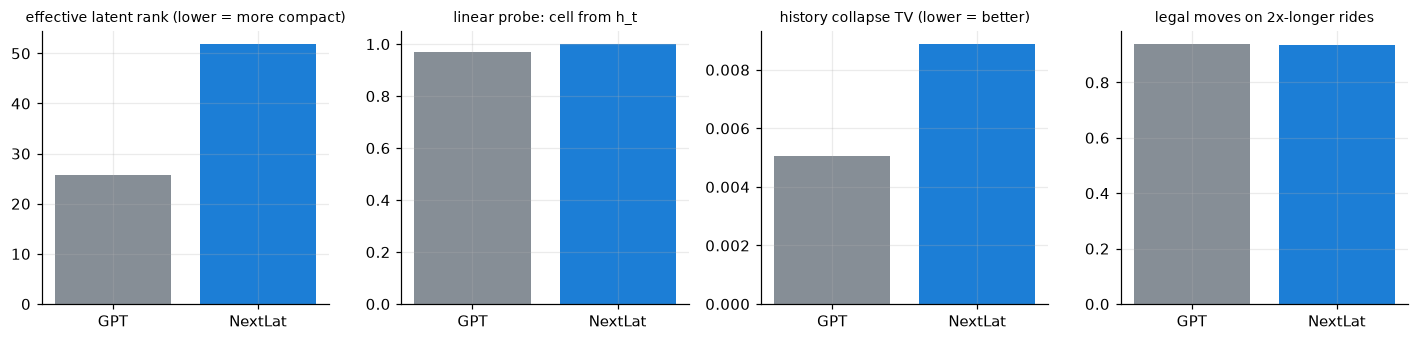

Verdicts from THIS run (one seed, toy scale):
  effective rank   : NextLat is NOT more compact here: its rank is higher (paper's claim NOT reproduced on this toy)
  linear state probe: NextLat encodes the cell more linearly
  history collapse : GPT collapses same-state histories more (paper's compression claim NOT reproduced on this toy)


In [12]:
fig, axs = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, (k, t) in zip(axs, [("rank", "effective latent rank (lower = more compact)"), ("probe", "linear probe: cell from h_t"), ("collapse", "history collapse TV (lower = better)"), ("legal_long", "legal moves on 2x-longer rides")]):
    ax.bar(["GPT", "NextLat"], [M["GPT"][k], M["NextLat (d=1)"][k]], color=[GPT_C, NL_C]); ax.set_title(t, fontsize=9)
plt.tight_layout(); plt.show()
print("Verdicts from THIS run (one seed, toy scale):")
print("  effective rank   :", "NextLat is more compact (paper's claim reproduced)" if verdict["rank"] == "NextLat" else "NextLat is NOT more compact here: its rank is higher (paper's claim NOT reproduced on this toy)")
print("  linear state probe:", "NextLat encodes the cell more linearly" if verdict["probe"] == "NextLat" else "GPT encodes the cell more linearly")
print("  history collapse :", "NextLat collapses same-state histories more" if verdict["collapse"] == "NextLat" else "GPT collapses same-state histories more (paper's compression claim NOT reproduced on this toy)")

**How to read the table.** The paper's Figure 3 shows reconstructed city maps for each method; NextLat's has sparse, local inconsistencies where the baselines have many:

<img src="nextlat_assets/fig3_maps.png" width="760"/>

*Figure 3 of the paper: maps reconstructed from taxi-ride transformers (red edges are inconsistencies with the true map). Notice NextLat (d) has visibly fewer red edges; this is qualitative, on one model per method.*

Our toy's measurements are the numbers printed above. Four cautions before reading anything into them: one seed per model; a 50-cell world, far simpler than 4,580 intersections; both models already solve the task, so every difference is about *representation*, not accuracy; and the effective-rank metric depends on how many distinct states exist, so its absolute value is not comparable to the paper's 52.7 and 160.1. The verdict lines above say which direction each metric went in this run, including where it went against the paper.

## Horizon and the KL term

The paper's theory needs only horizon `d = 1`; larger horizons and the KL term are described as extra training signal, and in the limitations section they say it is "unclear whether multi-step supervision (d > 1) and KL token-level supervision are even necessary at larger model and data scales". So we ablate on our toy: horizon 4 (with KL), and horizon 1 without the KL term. Same seed, data and steps.

In [13]:
t0 = time.time(); nl4, dyn4, _ = train_model(world, "nextlat", steps=STEPS, horizon=4, log_every=1500); print(f"NextLat d=4: {time.time() - t0:.0f}s")
t0 = time.time(); nl_nokl, dyn_nokl, _ = train_model(world, "nextlat", steps=STEPS, horizon=1, use_kl=False, log_every=1500); print(f"NextLat d=1 no KL: {time.time() - t0:.0f}s")
M["NextLat (d=4)"] = measure(nl4, "NextLat (d=4)"); M["NextLat (d=1, no KL)"] = measure(nl_nokl, "NextLat (d=1, no KL)")
names = ["GPT", "NextLat (d=1)", "NextLat (d=4)", "NextLat (d=1, no KL)"]
print(f"{'measurement':52s}" + "".join(f"{n:>22s}" for n in names))
for lab, k, f, _ in rows: print(f"{lab[:50]:52s}" + "".join(f"{f.format(M[n][k]):>22s}" for n in names))
check("every variant learned the world (>= 99% legal next moves)", all(M[n]["legal"] >= 0.99 for n in names))

  step  1500  next-token loss 1.2813  (125s)


  step  3000  next-token loss 1.1144  (250s)
NextLat d=4: 251s


  step  1500  next-token loss 1.2256  (103s)


  step  3000  next-token loss 1.1110  (209s)
NextLat d=1 no KL: 209s


measurement                                                            GPT         NextLat (d=1)         NextLat (d=4)  NextLat (d=1, no KL)
legal next move (in-distribution)                                    1.000                 1.000                 1.000                 1.000
legal next move, 48-move rides (2x training length                   0.938                 0.936                 0.934                 0.940
legal next move, biased rides (OOD)                                  1.000                 1.000                 1.000                 1.000
effective latent rank                                                 25.8                  51.8                  42.4                  50.3
linear probe: cell from h_t                                          0.969                 1.000                 0.982                 0.997
linear probe on 48-move rides                                        0.592                 0.625                 0.607                 0.614
history colla

Read the table row by row rather than for a winner: with one seed each, differences in the third decimal are noise we have not measured. Two things the paper leads us to look for, and that we can honestly say something about: whether adding horizon 4 changes the compactness and probe numbers relative to horizon 1, and whether removing the KL term does. The paper's cost data (Table 5) says horizon 4 is already noticeably slower to train; our toy shows the same kind of slowdown in the timings printed above (d=4 against d=1).

## Self-speculative decoding

**Concrete example.** Suppose the model must generate 5 more moves. Plain decoding runs the full transformer 5 times. Speculative decoding (Leviathan et al., 2023) lets a cheap *draft* guess several tokens, then runs the expensive model **once** to check them all and keeps the longest prefix it agrees with. NextLat gives a draft for free: roll the dynamics MLP forward in latent space (`h -> token -> h' -> token -> ...`), using the output head to read each token off, with no second model. Multi-token-prediction (MTP) models can only draft the fixed number of tokens they were trained for; NextLat's recursion can be run longer than the training horizon.

{img("fig2_speculative.png", 700)}

*Figure 2 of the paper. Left: MTP drafts a fixed length. Right: NextLat can chain its dynamics for a variable length. Notice that NextLat's longer drafts mean fewer draft-verify cycles; the paper notes it only varies a fixed draft length per prompt, and does not implement adaptive drafting.*

**The acceptance rule.** For a drafted token `x` with draft probability `q(x)` and the transformer's own probability `p(x)`, accept with probability `min(1, p(x)/q(x))`; on rejection, draw a replacement from `max(p - q, 0)` (normalised). This makes the output distribution **exactly** the transformer's. We verify that on arbitrary distributions before trusting it:

In [14]:
@torch.no_grad()
def accept_sample(p, q, g):
    """One speculative-sampling step (Leviathan et al., 2023): draw x ~ q, accept with prob min(1, p/q), otherwise redraw
    from the normalised residual max(p - q, 0). The returned token is distributed EXACTLY as p. Returns (token, was_accepted)."""
    x = torch.multinomial(q, 1, generator=g).item()
    if torch.rand(1, generator=g).item() < min(1.0, (p[x] / q[x]).item()): return x, True
    r = (p - q).clamp(min=0); return torch.multinomial(r / r.sum(), 1, generator=g).item(), False

@torch.no_grad()
def speculative_decode(model, dyn, start_tok, n_new, k, g, draft="latent"):
    """Self-speculative decoding. ONE model: the transformer verifies, the latent-dynamics MLP drafts.
    Each cycle: take the pending exact token x1; draft k more tokens by rolling the dynamics model forward in latent space
    (h -> token -> h' -> token ...); run the transformer ONCE over x1 + drafts; accept drafts left-to-right while they pass.
    Tokens committed per cycle = 1 (x1) + accepted drafts.   draft='uniform' replaces the dynamics model by a know-nothing draft."""
    S = [start_tok]; logits, h = model(torch.tensor([S])); h_last = h[0, -1]
    pending = torch.multinomial(logits[0, -1, :4].softmax(-1), 1, generator=g).item()
    accepted_per_cycle, pos_try, pos_acc = [], np.zeros(max(k, 1)), np.zeros(max(k, 1))
    while len(S) - 1 < n_new:
        x1 = pending; drafts, qs = [], []
        hc = dyn(h_last, torch.tensor(x1)) if draft == "latent" else None
        for j in range(k):
            q = model.head(hc)[:4].softmax(-1) if draft == "latent" else torch.full((4,), 0.25)
            d = torch.multinomial(q, 1, generator=g).item(); drafts.append(d); qs.append(q)
            if draft == "latent" and j < k - 1: hc = dyn(hc, torch.tensor(d))
        n_old = len(S); logits, h = model(torch.tensor([S + [x1] + drafts]))                # the single verification pass
        a, pending = 0, None
        for j in range(k):
            p = logits[0, n_old + j, :4].softmax(-1); pos_try[j] += 1
            u = torch.rand(1, generator=g).item()
            if u < min(1.0, (p[drafts[j]] / qs[j][drafts[j]]).item()): a += 1; pos_acc[j] += 1
            else:
                r = (p - qs[j]).clamp(min=0); pending = torch.multinomial(r / r.sum(), 1, generator=g).item(); break
        if pending is None: pending = torch.multinomial(logits[0, -1, :4].softmax(-1), 1, generator=g).item()   # bonus token
        S = S + [x1] + drafts[:a]; h_last = h[0, n_old + a]; accepted_per_cycle.append(a)
    return S[:n_new + 1], accepted_per_cycle, pos_try, pos_acc

@torch.no_grad()
def plain_sample(model, start_tok, n_new, g):
    S = [start_tok]
    for _ in range(n_new): S.append(torch.multinomial(model(torch.tensor([S]))[0][0, -1, :4].softmax(-1), 1, generator=g).item())
    return S

In [15]:
g = torch.Generator().manual_seed(0)
for trial in range(3):
    p = torch.rand(4, generator=g).pow(2); p /= p.sum(); q = torch.rand(4, generator=g); q /= q.sum()
    counts = np.zeros(4); acc = 0; N = 40000
    for _ in range(N):
        x, ok = accept_sample(p, q, g); counts[x] += 1; acc += ok
    tv = 0.5 * np.abs(counts / N - p.numpy()).sum()
    print(f"trial {trial}: TV(output, p) = {tv:.4f}   acceptance rate {acc / N:.2f}   (1 - TV(p,q) = {1 - 0.5 * (p - q).abs().sum().item():.2f})")
    check(f"speculative sampling returns tokens distributed as the target p (trial {trial})", tv < 0.01)

trial 0: TV(output, p) = 0.0039   acceptance rate 0.44   (1 - TV(p,q) = 0.43)
PASS  speculative sampling returns tokens distributed as the target p (trial 0)


trial 1: TV(output, p) = 0.0021   acceptance rate 0.64   (1 - TV(p,q) = 0.64)
PASS  speculative sampling returns tokens distributed as the target p (trial 1)


trial 2: TV(output, p) = 0.0020   acceptance rate 0.56   (1 - TV(p,q) = 0.56)
PASS  speculative sampling returns tokens distributed as the target p (trial 2)


**One cycle in code (read `speculative_decode` above).** (1) The transformer's last hidden state gives the exact next token `x1`. (2) The dynamics MLP rolls `k` steps forward in latent space and the output head turns each predicted state into a draft distribution `q`. (3) **One** transformer pass over `x1` and the `k` drafts yields the true distributions `p` at every draft position. (4) Drafts are accepted left to right; the first rejection is replaced by a draw from the residual, and if all pass, one bonus token is drawn. Each cycle therefore costs one transformer pass and commits `1 + (accepted drafts)` tokens, which is the paper's accounting ("accepted tokens excludes the next-token prediction, which is always accepted").

We measure the **average accepted tokens per cycle** for draft lengths 1 to 10 on rides starting from a random cell, for the two NextLat models and for a *know-nothing* uniform draft (`q` = 0.25 for each move) as a baseline. The uniform draft matters: in a world where most cells have 2-4 legal moves, even a draft that knows nothing gets accepted fairly often, so a good draft must beat it.

  draft length k       1       2       4       6       8      10
NextLat d=1 (latent draft)        0.93    1.76    3.18    4.12    5.23    5.53
NextLat d=4 (latent draft)        0.91    1.80    3.12    4.44    5.38    6.02
uniform draft (know-nothing)      0.86    1.42    2.49    3.52    3.34    3.90
(average accepted draft tokens per cycle; a cycle also commits 1 exact token)


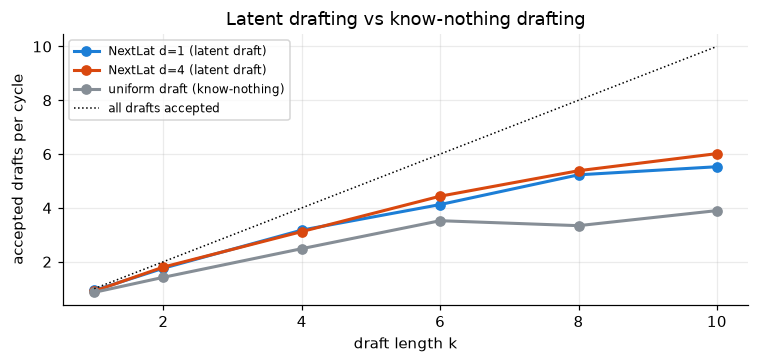

PASS  with k=1 at most one draft can be accepted; with k=10 no more than 10
PASS  the latent draft is accepted more often than the know-nothing uniform draft at k=4   [3.18 vs 2.49]


In [16]:
def run_spec(model, dyn, k, draft, n_runs=48, n_new=40, seed=0):
    g = torch.Generator().manual_seed(seed); rng = np.random.default_rng(seed); acc, tries, accs = [], 0, 0; legal_steps = []
    for r in range(n_runs):
        start = world.start_token(int(rng.choice(world.start_choices)))
        S, a, pt, pa = speculative_decode(model, dyn, start, n_new, k, g, draft)
        acc += a; tries += pt; accs += pa
    return float(np.mean(acc)), np.asarray(accs) / np.maximum(tries, 1)

ks = [1, 2, 4, 6, 8, 10]
curves = {"NextLat d=1 (latent draft)": [], "NextLat d=4 (latent draft)": [], "uniform draft (know-nothing)": []}
for k in ks:
    curves["NextLat d=1 (latent draft)"].append(run_spec(nl1, dyn1, k, "latent")[0])
    curves["NextLat d=4 (latent draft)"].append(run_spec(nl4, dyn4, k, "latent")[0])
    curves["uniform draft (know-nothing)"].append(run_spec(nl1, dyn1, k, "uniform")[0])
print(f"{'draft length k':>16s}" + "".join(f"{k:>8d}" for k in ks))
for n_, c_ in curves.items(): print(f"{n_:>16s}"[:30].ljust(30) + "".join(f"{v:8.2f}" for v in c_))
print("(average accepted draft tokens per cycle; a cycle also commits 1 exact token)")
fig, ax = plt.subplots(figsize=(7, 3.4))
for (n_, c_), col in zip(curves.items(), [NL_C, ACC_C, GPT_C]): ax.plot(ks, c_, "o-", lw=2, color=col, label=n_)
ax.plot(ks, ks, ":", color="k", lw=1, label="all drafts accepted"); ax.set_xlabel("draft length k"); ax.set_ylabel("accepted drafts per cycle"); ax.set_title("Latent drafting vs know-nothing drafting"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
check("with k=1 at most one draft can be accepted; with k=10 no more than 10", curves["NextLat d=1 (latent draft)"][0] <= 1 and curves["NextLat d=1 (latent draft)"][-1] <= 10)
check("the latent draft is accepted more often than the know-nothing uniform draft at k=4", curves["NextLat d=1 (latent draft)"][ks.index(4)] > curves["uniform draft (know-nothing)"][ks.index(4)], f"{curves['NextLat d=1 (latent draft)'][ks.index(4)]:.2f} vs {curves['uniform draft (know-nothing)'][ks.index(4)]:.2f}")

In [17]:
# Does speculative decoding really leave the output distribution alone? Compare how legal the generated rides are.
g1, g2 = torch.Generator().manual_seed(11), torch.Generator().manual_seed(12); rng = np.random.default_rng(3)
def legal_fraction(S):
    cell = [c for c in range(world.n_cells) if world.start_token(c) == S[0]][0]; ok = 0
    for m in S[1:]:
        if world.legal[cell, m]: ok += 1; cell = world.next_cell[cell, m]
        else: break
    return ok / (len(S) - 1)
spec_l, plain_l = [], []
for r in range(48):
    start = world.start_token(int(rng.choice(world.start_choices)))
    spec_l.append(legal_fraction(speculative_decode(nl1, dyn1, start, 40, 6, g1)[0])); plain_l.append(legal_fraction(plain_sample(nl1, start, 40, g2)))
print(f"legal-prefix fraction of generated rides:  speculative (k=6) {np.mean(spec_l):.3f}   plain sampling {np.mean(plain_l):.3f}")
check("speculative decoding preserves the quality of the generated rides (within 0.08 of plain sampling)", abs(np.mean(spec_l) - np.mean(plain_l)) < 0.08)

legal-prefix fraction of generated rides:  speculative (k=6) 0.826   plain sampling 0.837
PASS  speculative decoding preserves the quality of the generated rides (within 0.08 of plain sampling)


In [18]:
# Modeled speedup. Hardware-dependent, so we MEASURE the relative cost of one draft step and plug it into the paper's accounting:
#   plain decoding: 1 transformer pass per token.   speculative: 1 pass + k draft steps per cycle, committing 1 + accepted tokens.
import time
seq = torch.tensor([[world.start_token(0)] + [0] * 39])
with torch.no_grad():
    t0 = time.perf_counter()
    for _ in range(100): nl1(seq)
    t_fwd = (time.perf_counter() - t0) / 100
    h = torch.randn(128); tk = torch.tensor(0); t0 = time.perf_counter()
    for _ in range(100): nl1.head(dyn1(h, tk))
    t_draft = (time.perf_counter() - t0) / 100
c = t_draft / t_fwd
print(f"one draft step costs {c:.2f} of a transformer pass on this CPU (toy model; for a 1.3B model on a GPU this ratio is far smaller)")
modeled = [(1 + a_) / (1 + k * c) for k, a_ in zip(ks, curves["NextLat d=1 (latent draft)"])]
for k, a_, s_ in zip(ks, curves["NextLat d=1 (latent draft)"], modeled): print(f"k={k:>2d}: accepted {a_:.2f} -> modeled speedup {s_:.2f}x")
check("the modeled speedup formula gives exactly 1 when nothing is accepted and drafting is free", abs((1 + 0) / (1 + 5 * 0.0) - 1) < 1e-12)

one draft step costs 0.01 of a transformer pass on this CPU (toy model; for a 1.3B model on a GPU this ratio is far smaller)
k= 1: accepted 0.93 -> modeled speedup 1.91x
k= 2: accepted 1.76 -> modeled speedup 2.70x
k= 4: accepted 3.18 -> modeled speedup 4.01x
k= 6: accepted 4.12 -> modeled speedup 4.82x
k= 8: accepted 5.23 -> modeled speedup 5.74x
k=10: accepted 5.53 -> modeled speedup 5.90x
PASS  the modeled speedup formula gives exactly 1 when nothing is accepted and drafting is free


**What we found, and how it compares with the paper.** The accepted-token table above is our measurement on a toy world. The *modeled* speedup is not a wall-clock result: we measured one draft step at about 0.01 of a transformer pass on this CPU, and that near-zero cost is what lets the model credit almost every accepted token as a saving (up to about 5.9x at k=10). Treat it as the formula applied to our acceptance numbers, not as evidence for a speedup; the paper's 3.3x is the measured figure, on 1.3B-parameter models and B200 GPUs. The paper's 1.3B models, on 8 B200 GPUs, report average accepted tokens of 4.59 (NextLat d=2, Wikipedia) against 1.72 for MTP d=2, and a speedup of up to 3.3x on FineWeb-Edu as the draft length grows (Figure 8a), with fully accepted drafts persisting at length 10 (Figure 8b):

<img src="nextlat_assets/fig8_speedup.png" width="700"/>

*Figure 8 of the paper. (a) speedup vs draft length, rising sublinearly; (b) probability the whole draft is accepted vs draft length. Notice NextLat's bars remain non-zero out to length 10, beyond its training horizon of 1 or 2.*

The thing our toy can check is the ingredient behind it: a draft produced by rolling the learned dynamics forward in latent space is accepted more often than a draft that knows nothing (the check above), so the learned transitions carry real information. It cannot tell us the size of the effect on language.

## Costs, what failed, and what is open

**Costs.** From the paper's Table 5 (training on FineWeb-Edu, one B200, 33k-token batches): training parameters 1.40B vs 1.32B for GPT; training speed 3.09 steps/s at horizon 1 (equal to GPT), 2.79 at horizon 2 and 1.73 at horizon 8; inference parameters unchanged. Belief State Transformers, the other belief-state method they compare with, train at 0.89 steps/s with 2.57B parameters, which is over 3x slower than NextLat. On language-modeling perplexity NextLat is not free: FineWeb-Edu perplexity is 10.83 (d=1) against 10.52 for GPT, though better than MTP (10.90) and JTP (11.08). Zero-shot accuracy gains are modest (59.21 for NextLat d=2 against 58.82), and the paper itself says larger models may be needed to see more.

**What failed or did not reproduce here.** (1) On our toy the effective-rank and history-collapse measurements did not both favour NextLat; the verdict lines in step 4 say which ones did and did not. (2) Both models solved the task exactly, so next-token accuracy could not discriminate, as the paper also observes. (3) We did not implement the paper's other benchmarks (Countdown, Path-Star graphs, TinyStories, FineWeb-Edu pre-training), the baselines BST and JTP, or Manhattan itself; none of the paper's numbers above is ours.

**Open work the paper names.** The design space of the latent dynamics model (they use plain MLPs); whether multi-step and KL terms are needed at scale; adaptive draft lengths (their speculative decoding uses a fixed draft length per prompt); applying NextLat as a fine-tuning objective on pretrained models; and the training sensitivity they report: the next-hidden-state loss can rise during training and behaves differently across optimisers (their Appendix E).

## Closing thoughts

Self-predictive learning has a long history in reinforcement learning (the paper cites work from Gelada et al., 2019 to Ni et al., 2024), and belief states go back to Kaelbling et al., 1998. NextLat's contribution, as Teoh et al. frame it, is a way to ask a transformer for that old inductive bias while leaving its architecture, parallel training and inference alone. What we verified are the mechanics (loss, gradient routing, acceptance rule) and a small controlled comparison whose direction on each metric is printed above. Credit for the method, theory and all reported results belongs to Teoh, Tomar, Ahn, Hu, Pearce, Sharma, Krishnamurthy, Islam, Lamb and Langford.

**Claims that lack a number or baseline, for you to fix:** (1) every toy comparison is one seed on one 50-cell world, so a different seed could reorder close rows; (2) the effective-rank metric depends on the number of states, so our values are not comparable with the paper's; (3) the "modeled speedup" uses a CPU timing of a toy model and is not a transferable measurement; (4) the theory (Theorem 3.2) applies to an idealised, perfectly trained model, and we did not test how close a trained network gets beyond the probe; (5) all paper numbers are quoted, not reproduced.

In [19]:
print(f"{sum(ok for _, ok in CHECKS)}/{len(CHECKS)} checks passed")
for n, ok in CHECKS:
    if not ok: print("FAILED:", n)
assert all(ok for _, ok in CHECKS), "some checks failed"

16/16 checks passed
